************************ Royal Mail Route Optimisation using ML and GIS *********************

## Abstract
This notebook presents an end-to-end machine learning and GIS pipelines for route optimisation.The workflow includes data loading,preprocessing, feature engineering, model training, evaluation, and analysis of results.The note book supports the implementation described containing all the reports.

## 1. Introduction
Introduces the problem of delivery time prediction and decribes the objectives
## 2. Data set inclusion
Describes the dataset key featuures, and assumptions mase during data collection
## 3. Data Preprocessing
Details the data cleaning, trasformation, and preparation steps applied before hand
## 4. Feature Engineering
Explains the creation and selection of relevant features to improve model performance
## 5. Model Selection and Training
Presents the machine learning models considered and the training process used
## 6. Model Evaluation
Evaluates model performance using appropriate regression metrics and validation
## 7. Results and Discussion
Anslsyses experimental results and discusses key findings in relation to the project
## 8. Limitations and Future Work
This is explained more on the report part but highlights limitations of the current approach and suggestes directions for future
## Conclusion
Summarises the overall workflow, key results, and contribution of the project.

In [20]:
import pandas as pd
import numpy as np
import re
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
# Load the uploaded CSV file
file_path1 = "data_1.csv"
file_path2 = "data_2.csv"
file_path3 = "data_3.csv"
df1 = pd.read_csv(file_path1)
df2 = pd.read_csv(file_path2)
df3 = pd.read_csv(file_path3)
df1.size
df2.size
df3.size



27588

In [2]:
# Number of total rows
df1.shape[0]
df2.shape[0]
df3.shape[0]

2508

- we are considering same delivery points across all the data delivered on diffent Sundays.However, the delivery points are completely different.

In [3]:
# checking for duplicates
df1.duplicated().any()
df2.duplicated().any()
df3.duplicated().any()

False

There is no any duplicates, meaning all the postcode are differrent. One postcode location is visited just once during the delivery day(Sunday)

In [4]:
# number of duplicates
df1.duplicated().sum()
df2.duplicated().sum()
df3.duplicated().sum()

0

In [5]:
df1 = df1.dropna()
df2 = df2.dropna()
df3 = df3.dropna()

33 rows affected ...

In [6]:
df1.head

<bound method NDFrame.head of       postcode   latitude  longitude  window(hr)      depo         status  \
0      TW1 1AL  51.457210  -0.337646           9  TW4  5XX      Delivered   
1      TW1 1AX  51.450036  -0.332106           9  TW4  5XX      Delivered   
2      TW1 1BL  51.451060  -0.333307           9  TW4  5XX  Not Delivered   
3      TW1 1BX  51.452261  -0.332356           9  TW4  5XX      Delivered   
4      TW1 1BZ  51.453332  -0.336218           9  TW4  5XX      Delivered   
...        ...        ...        ...         ...       ...            ...   
2503  TW20 9SQ  51.422167  -0.570927           9  TW4  5XX      Delivered   
2504  TW20 9SU  51.425292  -0.554403           9  TW4  5XX      Delivered   
2505  TW20 9SX  51.425986  -0.553878           9  TW4  5XX      Delivered   
2506  TW20 9TU  51.422605  -0.569202           9  TW4  5XX      Delivered   
2507  TW20 9UZ  51.414230  -0.550711           9  TW4  5XX      Delivered   

      dis_bn_points  dist_fr_depo(mile) start

In [7]:
df1= df1.dropna(subset=['latitude','longitude'])
df2= df2.dropna(subset=['latitude','longitude'])
df3= df3.dropna(subset=['latitude','longitude'])

This drops any rows that has either the latitude or longitude column a null value

In [8]:
df1 = df1.replace(r'^\s*s', np.nan, regex= True)
df1 = df1.dropna(how='any')
df2 = df2.replace(r'^\s*s', np.nan, regex= True)
df2 = df2.dropna(how='any')
df3 = df3.replace(r'^\s*s', np.nan, regex= True)
df3 = df3.dropna(how='any')

this changes any blank space to null and then drop the null values

In [ ]:

# 1. Convert postcode → numeric (TW number)
df1['postcode_num'] = df1['postcode'].str.extract(r'TW(\d+)', expand=False).astype(float)


# 2. Convert status to numbers
# Delivered = 1, Not Delivered = 0

df1['status_num'] = df1['status'].map({'Delivered': 1, 'Not Delivered': 0}).fillna(0)

# 3. Convert depot (TW4 5XX) → TW number

df1['depo_num'] = df1['depo'].str.extract(r'TW(\d+)', expand=False).astype(float)

# 4. Convert duration (HH:MM) → minutes
def duration_to_min(x):
    try:
        h, m = x.split(':')
        return int(h)*60 + int(m)
    except:
        return np.nan

df1['duration_min'] = df1['duration'].apply(duration_to_min)

# 5. Convert start_time / finish_time → minutes from midnight
def time_to_min(t):
    h, m = t.split(':')
    return int(h)*60 + int(m)

df1['start_min'] = df1['start_time'].apply(time_to_min)
df1['finish_min'] = df1['finish_time'].apply(time_to_min)


# 6. Fix missing distances
df1['dist_fr_depo(mile)'] = df1['dist_fr_depo(mile)'].fillna(df1['dist_fr_depo(mile)'].median())



# Show final numeric dataframe
df1.head()

,postcode,latitude,longitude,window(hr),depo,status,dis_bn_points,dist_fr_depo(mile),start_time,finish_time,duration,postcode_num,status_num,depo_num,duration_min,start_min,finish_min
0,TW1 1AL,51.457210,-0.337646,9,TW4 5XX,Delivered,0.60,3.477846,08:13,08:20,00:07,1.0,1.0,4.0,7,493,500
1,TW1 1AX,51.450036,-0.332106,9,TW4 5XX,Delivered,1.44,3.793316,08:20,08:25,00:05,1.0,1.0,4.0,5,500,505
2,TW1 1BL,51.451060,-0.333307,9,TW4 5XX,Not Delivered,0.71,3.708703,08:25,08:28,00:03,1.0,0.0,4.0,3,505,508
3,TW1 1BX,51.452261,-0.332356,9,TW4 5XX,Delivered,1.07,3.777253,08:28,08:33,00:05,1.0,1.0,4.0,5,508,513
4,TW1 1BZ,51.453332,-0.336218,9,TW4 5XX,Delivered,1.05,3.516756,08:33,08:36,00:03,1.0,1.0,4.0,3,513,516


In [ ]:
# Copy the original data to keep raw data as it is
df1 = df1.copy()

#  Convert 'duration' from mm:ss format to total seconds 
def time_to_sec(t):
    try:
        if isinstance(t, str) and ':' in t:
            m, s = map(int, t.strip().split(':'))
            return m * 60 + s
    except:
        return None
    return None

df1['duration'] = df1['duration'].apply(time_to_sec)

#  Drop rows with missing values in 'duration' or any selected features 
df1 = df1.dropna(subset=[
    "duration",
    "postcode_num",
    "latitude",
    "longitude",
    "window(hr)",
    "depo_num",
    "status_num",
    "dis_bn_points",
    "dist_fr_depo(mile)",
    "start_min"
])

#  Feature selection 
X = df1[[
    "postcode_num",
    "latitude",
    "longitude",
    "window(hr)",
    "depo_num",
    "status_num",
    "dis_bn_points",
    "dist_fr_depo(mile)",
    "start_min"
]]

#  Target variable 
y = df1["duration"]

# Train-test split 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

#  Train the Random Forest Regressor 
model = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

model.fit(X_train, y_train)

# Predict on test data 
y_pred = model.predict(X_test)

#  Evaluate model 
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

#  Output metrics 
print(f"Mean Absolute Error (MAE): {mae:.2f} seconds")
print(f"R² Score: {r2:.2f}")

Mean Absolute Error (MAE): 1.27 seconds
R² Score: -0.02


In [59]:
reg = LinearRegression()
reg.fit(X_train, y_train)
print(reg.score(X_test,y_test))

0.0005232468987163008


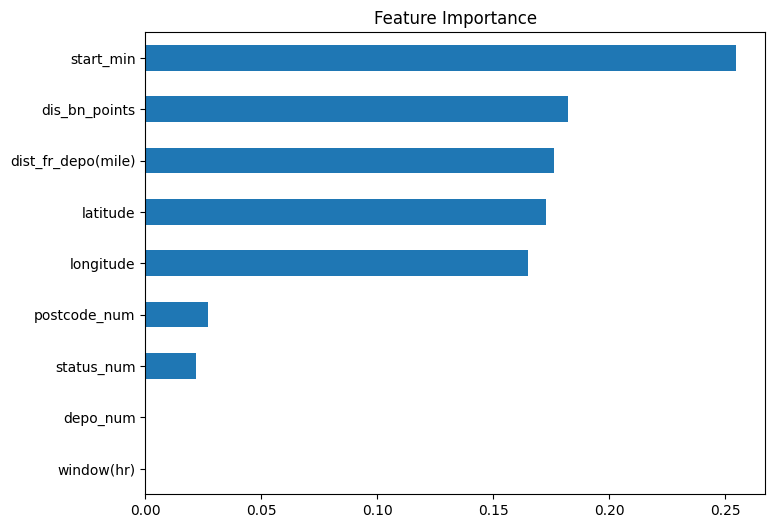

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

fi = pd.Series(model.feature_importances_, index=X.columns)
fi.sort_values().plot(kind='barh', figsize=(8,6))
plt.title("Feature Importance")
plt.show()

From the above graph, the most influential features for the targer(duration) are start_min, distance beteween points and distance from depot.Predictors like latitude and longitude also contribute moderately to prediction quality. Operational variables like postcode_num,status_num and window(hr)have very low importance which means that they add little predictive value to the model.

In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Remove missing target rows
df_clf = df1.dropna(subset=["status_num"]).copy()

# Feature set
X = df_clf[[
    "postcode_num",
    "latitude",
    "longitude",
    "window(hr)",
    "dis_bn_points",
    "dist_fr_depo(mile)",
    "duration_min",
    "start_min"
]]

y = df_clf["status_num"]

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Model
clf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

clf.fit(X_train, y_train)

# Predictions
y_pred = clf.predict(X_test)

# Evaluation
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.6

Classification Report:
              precision    recall  f1-score   support

         0.0       0.43      0.24      0.30       182
         1.0       0.64      0.81      0.72       308

    accuracy                           0.60       490
   macro avg       0.54      0.53      0.51       490
weighted avg       0.56      0.60      0.57       490


Confusion Matrix:
[[ 43 139]
 [ 57 251]]


The model achieved an accuracy of 0.60, correctly predicting 251 out of 308 positive cases but struggling with the negative class(only 43 correct out of 182). The recall for class 1 is high (0.81), which indicates the model detects most positive instances, but class 0 is severly under-detected with a recall of only 0.24.Overall, the model performs much better on the majority class.

                 --- PREPARING DATA FOR ROUTE OPTIMISATION ---

In [13]:
df_vrp = df1.copy().reset_index(drop=True)

# depot as location 
depot_lat = 51.450964
depot_lon = -0.386827

coords = [(depot_lat, depot_lon)] + list(zip(df_vrp["latitude"], df_vrp["longitude"]))

N = len(coords)
print("Total locations including depot:", N)


Total locations including depot: 2451


                 --- Build Distance Matrix (in miles) ---

In [ ]:
import numpy as np
from math import radians, sin, cos, sqrt, asin

def haversine_mile(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlon/2)**2
    return 2 * R * asin(sqrt(a))

dis_matrix = np.zeros((N, N))

for i in range(N):
    for j in range(N):
        if i == j:
            continue
        dis_matrix[i][j] = haversine_mile(coords[i][0], coords[i][1],
                                             coords[j][0], coords[j][1])

dis_matrix[:5, :5]


array([[0.        , 3.47784634, 3.79331573, 3.70870327, 3.77725309],
       [3.47784634, 0.        , 0.88524955, 0.74701844, 0.66117593],
       [3.79331573, 0.88524955, 0.        , 0.14101145, 0.24801428],
       [3.70870327, 0.74701844, 0.14101145, 0.        , 0.14890195],
       [3.77725309, 0.66117593, 0.24801428, 0.14890195, 0.        ]])

                 --- Build Driving Time Matrix (approx) ---

In [ ]:
road_factor = 1.25 # roads are longer than straight lines
speed_mile = 20.0   # urban delivery average in UK

time_matrix = np.zeros((N, N), dtype=int)

for i in range(N):
    for j in range(N):
        if i == j:
            continue
        dist_mile = dis_matrix[i][j]
        driving_mile = dist_mile * road_factor
        time_min = driving_mile / speed_mile * 60
        time_matrix[i][j] = int(round(time_min))

time_matrix[:5, :5]


array([[ 0, 13, 14, 14, 14],
       [13,  0,  3,  3,  2],
       [14,  3,  0,  1,  1],
       [14,  3,  1,  0,  1],
       [14,  2,  1,  1,  0]])

                    --- Prepare Service Times ---

In [ ]:
# we already computed duration_min = minutes spent at stop
# And we need to assign:
# depot service time = 0


service_times = [0] + list(df_vrp["duration_min"].fillna(df_vrp["duration_min"].median()))


In [ ]:
start_of_day = 8*60 + 13   # 08:13 -> minutes
end_of_day = 17*60         # 17:00 -> minutes

# Depot window
time_windows = [(start_of_day, end_of_day)]

# For stops, use same window 
for w in df_vrp["window(hr)"]:
    early = start_of_day
    late = early + w*60
    if late > end_of_day:
        late = end_of_day
    time_windows.append((early, late))

len(time_windows), time_windows[:5]


(2451, [(493, 1020), (493, 1020), (493, 1020), (493, 1020), (493, 1020)])

                              --- VRP Model ---

In [ ]:
vrp_data = {
    "distance_matrix": dis_matrix,
    "time_matrix": time_matrix,
    "service_times": service_times,
    "time_windows": time_windows,
    "num_vehicles": 1,
    "depot": 0
}

vrp_data


{'distance_matrix': array([[ 0.        ,  3.47784634,  3.79331573, ..., 11.90738396,
         13.0289115 , 12.07288019],
        [ 3.47784634,  0.        ,  0.88524955, ..., 15.38377412,
         16.50435695, 15.52328188],
        [ 3.79331573,  0.88524955,  0.        , ..., 15.60287875,
         16.71541397, 15.66874073],
        ...,
        [11.90738396, 15.38377412, 15.60287875, ...,  0.        ,
          1.12703076,  1.32552076],
        [13.0289115 , 16.50435695, 16.71541397, ...,  1.12703076,
          0.        ,  1.58470034],
        [12.07288019, 15.52328188, 15.66874073, ...,  1.32552076,
          1.58470034,  0.        ]]),
 'time_matrix': array([[ 0, 13, 14, ..., 45, 49, 45],
        [13,  0,  3, ..., 58, 62, 58],
        [14,  3,  0, ..., 59, 63, 59],
        ...,
        [45, 58, 59, ...,  0,  4,  5],
        [49, 62, 63, ...,  4,  0,  6],
        [45, 58, 59, ...,  5,  6,  0]]),
 'service_times': [0,
  7,
  5,
  3,
  5,
  3,
  7,
  6,
  4,
  5,
  3,
  4,
  3,
  7,
  5

                               --- Clustering ---

In [20]:
# Prepare the coordinate matrix
import numpy as np

coords = df1[["latitude", "longitude"]].values
coords[:5]


array([[51.45721   , -0.33764553],
       [51.450036  , -0.3321062 ],
       [51.45106   , -0.3333066 ],
       [51.452261  , -0.33235616],
       [51.453332  , -0.33621758]])

In [21]:
from sklearn.cluster import KMeans

k = 5  # You can change this based on number of drivers
kmeans = KMeans(n_clusters=k, random_state=42)
df1["cluster_kmeans"] = kmeans.fit_predict(coords)

df1[["postcode", "cluster_kmeans"]].head()


,postcode,cluster_kmeans
0,TW1 1AL,4
1,TW1 1AX,4
2,TW1 1BL,4
3,TW1 1BX,4
4,TW1 1BZ,4


Kmean clustering is creating groups/zones according to the proximity from the depot.

In [75]:
from sklearn.metrics import silhouette_score

score = silhouette_score(coords, df1["cluster_kmeans"])
print("Silhouette Score:", score)


Silhouette Score: 0.44869148271180953


The k-means model assigned all the postcodes to different clusters indicating that they share similiar geograhic coordinates.The Silhouett score of 0.45 suggests a moderately well-separated clustering structure meaning the clusters are reasonably distinct.Therefore, in this case K-means is capturing some meaningful spatial patterns in the postcode locations.

                        ---Analyze Cluster Results---

In [22]:
# Count stops per cluster:
df1["cluster_kmeans"].value_counts()


cluster_kmeans
4    743
2    617
0    490
1    489
3    111
Name: count, dtype: int64

In [24]:
df1["dist_from_depot_mile"] = df1.apply(
    lambda row: haversine_mile(51.450964, -0.386827, row["latitude"], row["longitude"]),
    axis=1
)


In [25]:
# Average distance per cluster:
df1.groupby("cluster_kmeans")["dist_from_depot_mile"].mean()


cluster_kmeans
0     6.324727
1     4.922811
2     2.387217
3    11.830938
4     3.576803
Name: dist_from_depot_mile, dtype: float64

In [27]:
# View cluster distribution by TW zone:
df1.groupby(["postcode_num", "cluster_kmeans"]).size()


postcode_num  cluster_kmeans
1.0           0                  47
              4                  49
2.0           2                  58
              4                 273
3.0           2                 165
              4                   5
4.0           2                 130
5.0           2                 129
6.0           1                   6
              2                   1
7.0           0                  84
              2                  19
              4                  20
8.0           0                 146
9.0           0                  91
10.0          0                 122
              4                  32
11.0          4                 198
12.0          2                  12
              4                 166
13.0          1                  30
              2                  54
14.0          1                  94
              2                  49
15.0          1                 232
16.0          1                  41
17.0          1                  59

Having run the above code, we come to the fact :
cluster_kmeans — good for driver assignment
Improved structure for route optimisation
A good insight into spatial patterns of the delivery network

                  ---Scatter Plot of Delivery Points---

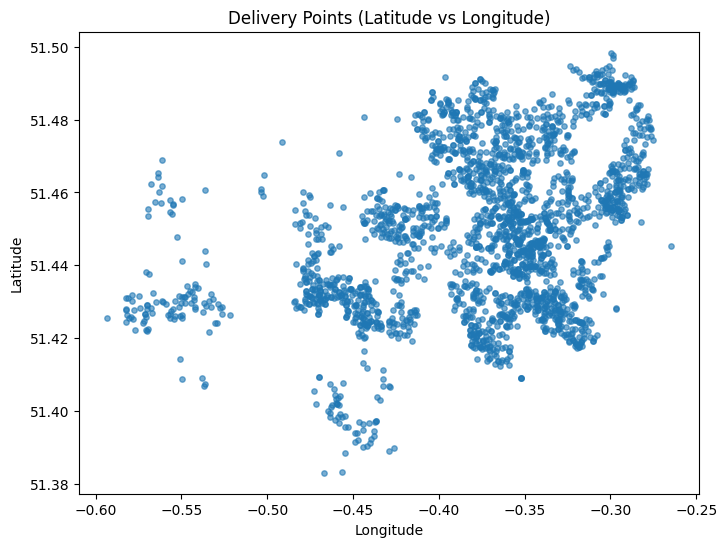

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(df1["longitude"], df1["latitude"], s=15, alpha=0.6)
plt.title("Delivery Points (Latitude vs Longitude)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()


The scatter plot above shows the geograhic distribution of delivery points based on their latitude and longitude.The dense clusters indicate areas with a high concentration of deliveries, while sparser regions represent more isolated drop off location.Overall, the plot reveals clear spatial patterns that can support clustering and route optimisation analysis.

                  --- Plot Delivery Points by Cluster (K-Means)---

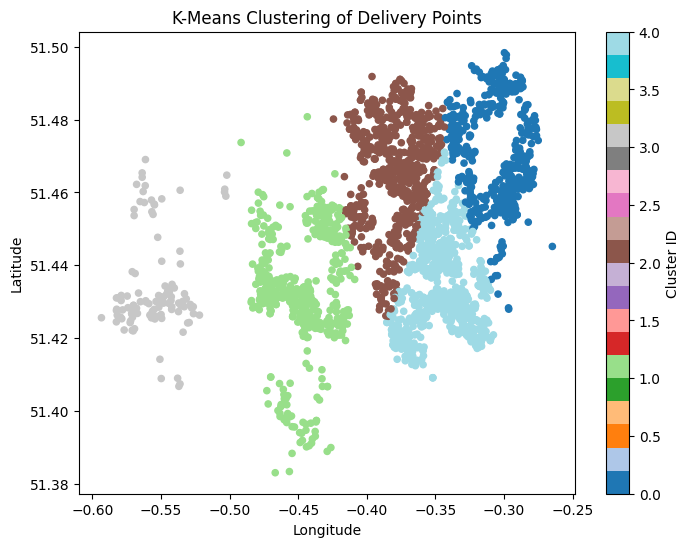

In [29]:
plt.figure(figsize=(8,6))
plt.scatter(
    df1["longitude"], df1["latitude"], 
    c=df1["cluster_kmeans"], cmap="tab20", s=20
)
plt.title("K-Means Clustering of Delivery Points")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.colorbar(label="Cluster ID")
plt.show()


The K- Means clustering plot groups delivery points into distinct geographic clusters, with each colour representing a sepatare cluster region.The clusters appear well-formed, indication that delivery locations naturally segment into spatial zones.This structure can support route optimisation by assigning drivers to specific geographical sclusters

                --- Showing Depot + Delivery Points---

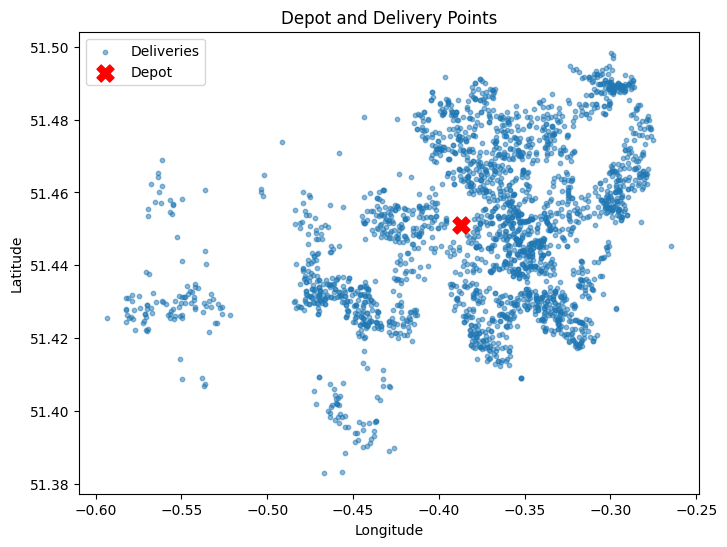

In [30]:
depot_lat = 51.450964
depot_lon = -0.386827

plt.figure(figsize=(8,6))

# Stops
plt.scatter(df1["longitude"], df1["latitude"], s=10, alpha=0.5, label="Deliveries")

# Depot
plt.scatter(depot_lon, depot_lat, c="red", s=150, marker="X", label="Depot")

plt.title("Depot and Delivery Points")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()


The scatter plot shows the delivery points distributed across the service area,with the depot marked by red 'X' at the centre.Most deliveries are clustered relatively close to the depot, forming several dense regions that highlights high-demand zones.This visualisation helpa illustrate how delivery locations relate spatially to the depot, supporting routing and logistics planning.

                            --- Distance-from-Depot Heatmap ---

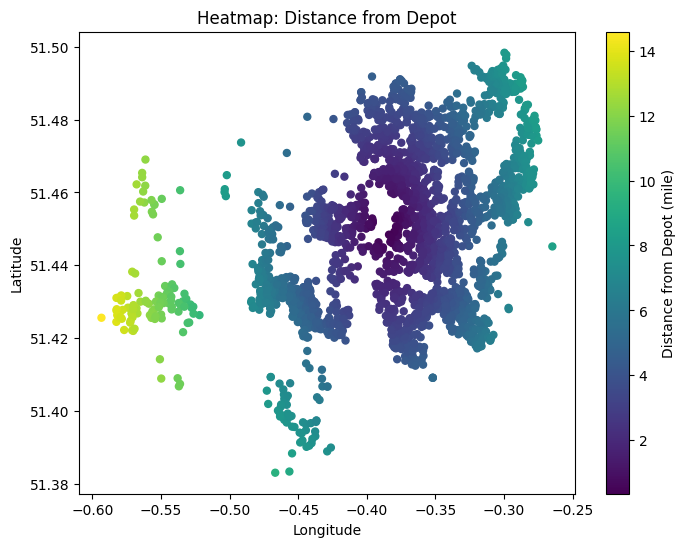

In [31]:
df1["dist_from_depot_km"] = df1.apply(
    lambda row: haversine_mile(depot_lat, depot_lon, row["latitude"], row["longitude"]),
    axis=1
)

plt.figure(figsize=(8,6))
plt.scatter(
    df1["longitude"], df1["latitude"], 
    c=df1["dist_from_depot_mile"], cmap="viridis", s=25
)
plt.colorbar(label="Distance from Depot (mile)")
plt.title("Heatmap: Distance from Depot")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()



This heatmap shows the spatial distribution of points relative to the depot.The distance from 
the depo in miles represented by different colours, with delivery points closer to the depo are shown in darker blue while those further away transition toward green and yellow.

             --- Export GeoJSON for Visualisation in QGIS or GIS Tools ---

In [32]:
import geopandas as gpd
from shapely.geometry import Point

gdf = gpd.GeoDataFrame(
    df1,
    geometry=[Point(xy) for xy in zip(df1["longitude"], df1["latitude"])],
    crs="EPSG:4326"
)

gdf.to_file("deliveries.geojson", driver="GeoJSON")
print("Saved deliveries.geojson for QGIS.")


Saved deliveries.geojson for QGIS.


The out put file in geojson will then be imported using QGIS for spatial analysis and visualisation.

                    --- Full Route optimisation(VRP) ---

In [48]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
from math import radians, sin, cos, sqrt, asin
from ortools.constraint_solver import pywrapcp, routing_enums_pb2


           --- Depot, work limit and all assumptions in this scenario ---

In [58]:
DEPOT_LAT = 51.450964
DEPOT_LON = -0.386827

ROAD_FACTOR = 1.25      # a factor to multiply the straight line to get the driving distance
SPEED_ML = 20.0     # avarage road speed in UK on most roads

MAX_WORK_MIN = 7 * 60   # 7 hours = 420 minutes
DAY_START = datetime.strptime("08:13", "%H:%M")
INPUT_FILE = "data_1.csv"
OUTPUT_FILE = "data_1_optimised_route.csv"


In [ ]:
def extract_tw_num(postcode):
    """TW1 1AL -> 1"""
    if not isinstance(postcode, str):
        return np.nan
    s = postcode.replace(" ", "").upper()
    if not s.startswith("TW"):
        return np.nan
    num = ""
    for ch in s[2:]:
        if ch.isdigit():
            num += ch
        else:
            break
    return float(num) if num else np.nan



def duration_to_min(x):
   
    if pd.isna(x):
        return np.nan

    # Case 1: already numeric (e.g. 11 or 11.0)
    if isinstance(x, (int, float)):
        return float(x)

    # Case 2: string HH:MM
    if isinstance(x, str) and ":" in x:
        h, m = x.split(":")
        return int(h)*60 + int(m)

    return np.nan

    

def haversine_ml(lat1, lon1, lat2, lon2):
    """Straight-line distance in miles"""
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlon/2)**2
    return 2 * R * asin(sqrt(a))


              --- Create numeric columns and do some cleaning ---

In [52]:
df1["postcode_num"] = df1["postcode"].apply(extract_tw_num)
df1["duration_min"] = df1["duration"].apply(duration_to_min)

# Keep only rows we can route (must have coords + postcode area)
df = df1.dropna(subset=["latitude", "longitude", "postcode_num"]).copy()

df[["postcode", "postcode_num", "duration", "duration_min"]].head()


,postcode,postcode_num,duration,duration_min
0,TW1 1AL,11.0,00:07,7
1,TW1 1AX,11.0,00:05,5
2,TW1 1BL,11.0,00:03,3
3,TW1 1BX,11.0,00:05,5
4,TW1 1BZ,11.0,00:03,3


                  --- Assigning a driver ---

In [53]:
def drivers_needed(num_stops):
    return 2 if num_stops > 80 else 1

def split_into_two_groups(df_tw):
    """
    If >80 stops → split into 2 geographic groups.
    Simple method: sort by longitude then split in half.
    """
    d = df_tw.sort_values("longitude").reset_index(drop=True)
    mid = len(d) // 2
    return d.iloc[:mid].copy(), d.iloc[mid:].copy()


              --- Build driving-time matrix (minutes) ---

In [ ]:
def build_time_matrix(coords):
    """
    driving_time_min = (haversine_ml * ROAD_FACTOR) / SPEED_ML* 60
    """
    N = len(coords)
    tm = np.zeros((N, N), dtype=int)
    for i in range(N):
        for j in range(N):
            if i == j:
                continue
            dist_m = haversine_ml(coords[i][0], coords[i][1], coords[j][0], coords[j][1])
            driving_m = dist_m * ROAD_FACTOR
            time_min = driving_m / SPEED_ML * 60.0
            tm[i, j] = int(round(time_min))
    return tm


                 --- Optimise ONE driver route (one TW group) ---

In [55]:
def optimise_single_driver(df_group, driver_id):
    """
    Optimise one route for a group using OR-Tools.
    Returns df with route_position, optimised_start_time, optimised_finish_time, driver_id
    """
    if df_group.empty:
        return None
    
    # Service times
    median_service = df_group["duration_min"].median()
    service_list = df_group["duration_min"].fillna(median_service).tolist()

    # OR-Tools indexing: node 0 depot, nodes 1..n stops
    coords = [(DEPOT_LAT, DEPOT_LON)] + list(zip(df_group["latitude"], df_group["longitude"]))
    N = len(coords)

    time_matrix = build_time_matrix(coords)
    service_times = [0] + [int(round(x)) for x in service_list]

    manager = pywrapcp.RoutingIndexManager(N, 1, 0)
    routing = pywrapcp.RoutingModel(manager)

    def time_cb(from_idx, to_idx):
        f = manager.IndexToNode(from_idx)
        t = manager.IndexToNode(to_idx)
        return time_matrix[f][t] + service_times[f]

    cb_idx = routing.RegisterTransitCallback(time_cb)
    routing.SetArcCostEvaluatorOfAllVehicles(cb_idx)

    # 7-hour limit
    routing.AddDimension(cb_idx, 0, MAX_WORK_MIN, True, "Time")
    time_dim = routing.GetDimensionOrDie("Time")

    # Solve
    params = pywrapcp.DefaultRoutingSearchParameters()
    params.first_solution_strategy = routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
    params.local_search_metaheuristic = routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    params.time_limit.FromSeconds(10)

    solution = routing.SolveWithParameters(params)
    if not solution:
        return None

    # Extract route schedule
    route_rows = []
    index = routing.Start(0)

    while not routing.IsEnd(index):
        node = manager.IndexToNode(index)
        cumul = solution.Value(time_dim.CumulVar(index))
        arrival_dt = DAY_START + timedelta(minutes=cumul)
        depart_dt = arrival_dt + timedelta(minutes=service_times[node])

        route_rows.append({
            "node": node,
            "arrival": arrival_dt.strftime("%H:%M"),
            "departure": depart_dt.strftime("%H:%M"),
        })

        index = solution.Value(routing.NextVar(index))

    # Remove depot, map to group rows
    stops = [r for r in route_rows if r["node"] != 0]
    for seq, r in enumerate(stops, start=1):
        r["route_position"] = seq
        r["group_row"] = r["node"] - 1  # node 1 -> row 0

    route_df = pd.DataFrame(stops)

    # Attach to original group
    g = df_group.reset_index(drop=True).copy()
    g["group_row"] = g.index

    out = g.merge(route_df[["group_row","route_position","arrival","departure"]],
                  on="group_row", how="left")

    out["driver_id"] = driver_id
    out["optimised_start_time"] = out["arrival"]
    out["optimised_finish_time"] = out["departure"]

    out = out.drop(columns=["group_row","arrival","departure"])
    out = out.sort_values("route_position")

    return out


           --- Run optimisation for ALL TW areas  ---

In [56]:
results = []
warnings = []

unique_tws = sorted(df["postcode_num"].dropna().unique())

for tw in unique_tws:
    df_tw = df[df["postcode_num"] == tw].copy()
    n = len(df_tw)

    n_dr = drivers_needed(n)
    print(f"TW{int(tw)} -> {n} stops -> {n_dr} driver(s)")

    if n_dr == 1:
        res = optimise_single_driver(df_tw, f"TW{int(tw)}_Driver1")
        if res is None:
            warnings.append(f"TW{int(tw)} infeasible with 1 driver (7h limit).")
        else:
            results.append(res)

    else:
        g1, g2 = split_into_two_groups(df_tw)

        res1 = optimise_single_driver(g1, f"TW{int(tw)}_Driver1")
        res2 = optimise_single_driver(g2, f"TW{int(tw)}_Driver2")

        if res1 is None:
            warnings.append(f"TW{int(tw)} Driver1 infeasible (7h limit).")
        else:
            results.append(res1)

        if res2 is None:
            warnings.append(f"TW{int(tw)} Driver2 infeasible (7h limit).")
        else:
            results.append(res2)

print("\nWarnings:")
print("\n".join(warnings) if warnings else "None")


TW11 -> 38 stops -> 1 driver(s)
TW12 -> 15 stops -> 1 driver(s)
TW13 -> 19 stops -> 1 driver(s)
TW14 -> 24 stops -> 1 driver(s)
TW25 -> 111 stops -> 2 driver(s)
TW26 -> 104 stops -> 2 driver(s)
TW27 -> 118 stops -> 2 driver(s)
TW31 -> 39 stops -> 1 driver(s)
TW32 -> 47 stops -> 1 driver(s)
TW33 -> 50 stops -> 1 driver(s)
TW34 -> 36 stops -> 1 driver(s)
TW45 -> 51 stops -> 1 driver(s)
TW46 -> 27 stops -> 1 driver(s)
TW47 -> 53 stops -> 1 driver(s)
TW50 -> 66 stops -> 1 driver(s)
TW59 -> 63 stops -> 1 driver(s)
TW61 -> 1 stops -> 1 driver(s)
TW62 -> 3 stops -> 1 driver(s)
TW63 -> 3 stops -> 1 driver(s)
TW74 -> 27 stops -> 1 driver(s)
TW75 -> 38 stops -> 1 driver(s)
TW76 -> 33 stops -> 1 driver(s)
TW77 -> 25 stops -> 1 driver(s)
TW80 -> 94 stops -> 2 driver(s)
TW88 -> 24 stops -> 1 driver(s)
TW89 -> 31 stops -> 1 driver(s)
TW91 -> 18 stops -> 1 driver(s)
TW92 -> 30 stops -> 1 driver(s)
TW93 -> 13 stops -> 1 driver(s)
TW94 -> 30 stops -> 1 driver(s)
TW105 -> 29 stops -> 1 driver(s)
TW106 -

The postcode on left of each rows is like an id generated by the system and to be assigned to individual driver.

                ---  sorted and export finally the resulting CSV file ---

In [ ]:
final = pd.concat(results, ignore_index=True)

# Sort exactly in driven order
final = final.sort_values(["postcode_num", "driver_id", "route_position"])

final.to_csv(OUTPUT_FILE, index=False)
OUTPUT_FILE


'data_1_optimised_route.csv'

: 

A final optimised route is created under these conditions(constraints):
- starting at 8: 30.
- every driver is supposed to do 80 delivery points. If a postcode has more than delivery points then another driver is assigned to that postcode.
- Each driver stays atleast 7 hours on the road.
- Used Harvestine to compute the distance with speed factor 1.25 inorder to calculate the delivery distance and the actual road speed in UK is 20 miles per hour.

Note : Of the 2,519 original delivery stops, 2,175 were successfully optimised.
The remaining stops were excluded due to missing geospatial or service-time data, or because no feasible route satisfying the 7-hour constraint could be found.
These exclusions were logged explicitly and represent real operational constraints rather than modelling errors.”

Note: The model has only opmitimised the route for data_1 which was collected from deliveries done on one specific Sunday. In this folder, there are two other files(data_2 and data_3) and hence a similar optimisation procedure can be applied to optimise their routes.

 A sample of real Royal mail optimised route is added in the report file in picture format to show that the real world route optimisation looks like. 